# Pontin et al. (2025): strong coupling and dark modes of a pair of levitated nanoparticles

A. Pontin, Q. Deplano, A. Ranfagni, F. Marino and F. Marin,
*Strong coupling and dark modes in the motion of a pair of levitated nanoparticles*,
Phys. Rev. Lett. **135**, 073602 (2025), [doi:10.1103/t33b-f1b2](https://doi.org/10.1103/t33b-f1b2)
(open version: [arXiv:2502.08563v1](https://arxiv.org/abs/2502.08563v1), the only arXiv version, with the
supplement; all equation and figure numbers below refer to it).

Two silica spheres sit in the two foci of one bichromatic tweezer, about 9 μm apart along the tweezer
axis: one in the 1064 nm focus, one in the 976 nm focus. The cavity ($\kappa/2\pi$ = 57 kHz at 1064 nm) is
transparent at 976 nm, so only 1064 nm light is scattered into the cavity mode, by both particles:
particle 2 sees the out-of-focus 1064 nm field $\zeta E_1 e^{i\varphi}$. Lowering the 976 nm power
$P_\text{tw2}$ tunes particle 2's transverse frequencies through particle 1's, and each crossing of an
$x$ or $y$ mode of one particle with one of the other is avoided by about 1 kHz: strong coupling through
the cavity. Above each crossing the upper branch goes dark where the bare frequencies cross.

This notebook

1. builds the pair in levisim with a per-trap cavity drive (`Trap(cavity_drive_tweezer=..., cavity_drive_field_ratio=ζ)`),
   because the bead in the 976 nm trap scatters another tweezer's light than the one holding it;
2. compares the couplings from the stated parameters with the fitted ones;
3. reproduces the four eigenfrequencies against $P_\text{tw2}$ (Fig. 3) and the splittings, with the
   Coulomb coupling and Coulomb shift of the supplement, against data digitised from Figs. 3 and 4a;
4. checks linear stability across the scan;
5. reproduces the dark mode in the heterodyne spectrogram (Fig. 4) and its position.

Runtime: about a minute (printed at the end), most of it the grid search and the stability scan.

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| tweezer 1: wavelength, power, polarisation | 1064 nm, 250 mW, $\theta \simeq 45°$ to the cavity axis | main text; supplement Sec. I |
| tweezer 2: wavelength, power | 976 nm, 220-360 mW (steps of 3.5 mW), polarised orthogonally to tweezer 1 | main text; supplement Sec. I |
| waists | 0.58 μm (1064 nm), 0.53 μm (976 nm); printed without a unit | supplement Sec. III A (from fibre NA 0.098) |
| focus separation $r_{12}$ | 9 ± 1 μm | main text, Fig. 1 |
| particles | silica, nominal diameter 125 nm; density not stated (2200 kg/m³ here) | main text |
| charges | $\lvert q_1\rvert$ = 89 ± 10 e, $\lvert q_2\rvert$ = 71 ± 10 e (signs not stated) | main text |
| frequencies $(\Omega_z, \Omega_y, \Omega_x)/2\pi$ | particle 1: (19, 117, 124) kHz; particle 2 at 360 mW: (28, 148, 129) kHz; $\Omega_{z2}/2\pi$ = 23.3 kHz at 280 mW | main text; supplement Sec. II |
| cavity | FSR 3.07 GHz ($L$ = 48.8 mm), waist 31 μm, $\kappa/2\pi$ = 57 kHz | main text |
| detuning, pressure | $\Delta/2\pi$ = −425 kHz (red), $5 \times 10^{-6}$ mbar | main text |
| fitted: field ratio, phase, position, tilt | $\zeta$ = 0.35 ± 0.015, $\varphi$ = 172 ± 3°, $\phi_1$ = 1.225 ± 0.015 rad, $\theta_z$ = 0.75 ± 0.13° | main text; supplement Sec. II |
| fitted couplings | $(g_{x1}, g_{y1})/2\pi$ = (18.1 ± 0.6, 17.3 ± 0.5) kHz; $(\lvert g_{x2}\rvert, \lvert g_{y2}\rvert)/2\pi = (P_0/P_\text{tw2})^{1/4}$ (7.0 ± 0.3, 6.0 ± 0.2) kHz, $P_0$ = 220 mW | main text |
| Coulomb coupling | $g_C/2\pi \simeq$ 120 Hz | main text; supplement Eq. (37) |

The paper's model (supplement Eqs. (15)-(21)) eliminates the cavity: the four transverse modes
$(x_1, y_1, x_2, y_2)$ evolve with $D_{\alpha\beta} = \Omega_\alpha\delta_{\alpha\beta} + G_{\alpha\beta}$,
$G_{\alpha\beta} = g_\alpha g_\beta^*/(\Delta - \Omega_\beta - i\kappa/2) + g_\alpha^* g_\beta/(\Delta + \Omega_\beta + i\kappa/2)$,
plus the Coulomb matrix of Eq. (37). Particle 1 sits at $\phi_1$ on the standing wave and particle 2 at
$\phi_2 = \phi_1 + k r_{12}\theta_z$ (1.92 rad), 58 and 59 nm on either side of a node. The Coulomb force
also shifts the particles' separation by $\Delta z$ as $P_\text{tw2}$ changes (Eqs. (4)-(5)), which turns
the phase of particle 2's coupling to $\varphi - k\Delta z$.

**Mapping onto levisim.** levisim keeps the cavity as a degree of freedom (its full linear model), so it
does not need the adiabatic elimination. Both beads couple with the 1064 nm wavenumber and polarisation:
bead 2 is trapped by a 976 nm `Tweezer` (frequencies through `override_Ω_dict`), and its trap gets
`cavity_drive_tweezer` = tweezer 1 and `cavity_drive_field_ratio` = $\zeta$. levisim's $\Phi_n$ is the
paper's $\phi_n$ (couplings $g_x \propto -\sin^2\theta\sin\Phi$, $g_y \propto -\sin\theta\cos\theta\sin\Phi$, as in
Eqs. (6)-(7)); levisim's $\Delta = \omega_\text{tweezer} - \omega_\text{cavity}$ has the paper's sign
(red is $\Delta < 0$ in both). The paper's phase multiplies the coefficient of $\hat a$, whereas levisim's
tweezer phase multiplies that of $\hat a^\dagger$ ($G = g\,e^{+i\varphi_n}$), so levisim's $\varphi_2 = -\varphi$; the
eigenvalues do not depend on this sign. levisim does not model a direct mechanical coupling between beads,
so the Coulomb coupling is added to levisim's drift matrix in this notebook (`coulomb_drift`).

In [ ]:
import sys
import time
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))  # paper_tools.py sits next to this notebook

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.optimize import least_squares, minimize_scalar

from levisim.core.constants import π, ε0, c as c_light
from levisim.core.units import kHz, Hz, nm, μm, mbar, degrees, mW
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.logger import set_console_level
from levisim.physics.tweezer import Tweezer
from levisim.physics.bead import Bead
from levisim.multiphysics.multitrap import MultiTrap
from levisim.multiphysics.enums.quantum_linear_theory_method import QuantumLinearTheoryMethod

from paper_tools import heterodyne, mechanical_eigenfrequencies, load_digitised

set_plt_rcParams_to_xmgrace_style()
T_START = time.time()
data = load_digitised('pontin2025_fig3_fig4.json')

## Two tweezers, one cavity drive

`pontin_pair` builds the system at a given $P_\text{tw2}$. With `drive=False` the 976 nm tweezer would
drive the cavity itself, which is what levisim did before the per-trap cavity drive existed: it logs a
WARNING (the tweezers have different wavelengths, and one cavity mode is driven at one frequency) and
gives bead 2 the coupling of its own 976 nm focus, with the 976 nm wavenumber.

In [ ]:
K1064 = 2*π/(1064*nm)
L_CAV = c_light/(2*3.07e9)
R12 = 9*μm
ZETA, PHI, PHI1, THETA_Z = 0.35, 172*degrees, 1.225, 0.75*degrees
P_TW1 = 250*mW
R_BEAD, RHO = 62.5*nm, 2200.0
M_BEAD = RHO*4/3*π*R_BEAD**3


def pontin_pair(P2, Ω1=(124*kHz, 117*kHz, 19*kHz), Ω2_360=(129*kHz, 148*kHz, 28*kHz), ζ=ZETA, φ=PHI, ϕ1=PHI1,
                θz=THETA_Z, w1=0.58*μm, w2=0.53*μm, θ=45*degrees, drive=True, axes=2, **kwargs):
    """the pair at 976 nm power P2 [W]; φ is the paper's phase of particle 2's field (levisim φ2 = -φ)"""
    s = np.sqrt(P2/0.36)   # Ω ∝ √P for the 976 nm trap
    tweezer1 = Tweezer(Power=P_TW1, λ=1064*nm, wx0=w1, wy0=w1, θ=θ)
    tweezer2 = Tweezer(Power=P2, λ=976*nm, wx0=w2, wy0=w2, θ=θ + 90*degrees)
    beads = [Bead(r=R_BEAD, ρ=RHO, Φ=ϕ1), Bead(r=R_BEAD, ρ=RHO, Φ=ϕ1 + K1064*R12*θz)]
    trap2 = dict(override_Ω_dict=dict(x=Ω2_360[0]*s, y=Ω2_360[1]*s, z=Ω2_360[2]*s))
    if drive:
        trap2.update(cavity_drive_tweezer=tweezer1, cavity_drive_field_ratio=ζ)
    return MultiTrap(
        tweezers=[tweezer1, tweezer2], beads=beads, φn_dict={1: 0.0, 2: -φ},
        trap_kwargs=[dict(override_Ω_dict=dict(x=Ω1[0], y=Ω1[1], z=Ω1[2])), trap2],
        Cartesian_axes_per_trap=axes, gas_kwargs=dict(P=5e-6*mbar),
        cavity_kwargs=dict(L=L_CAV, w=31*μm, κ=57*kHz, Δ=-425*kHz),
        # reproduces published numbers: without the static cavity shifts (MultiTrap default since round 5)
        static_cavity_shifts=False, **kwargs,
    )


def couplings(m):
    return {label: abs(d.G)/kHz for label, d in m.dimensions.items()}


print('976 nm tweezer driving the cavity itself (wrong for this experiment):')
wrong = pontin_pair(0.22, drive=False)
print('  |g|/2π [kHz]:', {k: round(v, 2) for k, v in couplings(wrong).items()})
nominal = pontin_pair(0.22)
print('stated parameters (w = 0.58 μm, θ = 45°, d = 125 nm, ρ = 2200 kg/m³), P_tw2 = 220 mW:')
print('  |g|/2π [kHz]:', {k: round(v, 2) for k, v in couplings(nominal).items()})
print(f'  cavity driven at λ = {2*π*c_light/nominal.cavity.ωtw/nm:.1f} nm; g_x1 / paper = {couplings(nominal)["x1"]/18.1:.3f}')

976 nm tweezer driving the cavity itself (wrong for this experiment):
  |g|/2π [kHz]: {'x1': np.float64(24.63), 'y1': np.float64(25.36), 'x2': np.float64(30.52), 'y2': np.float64(28.49)}
stated parameters (w = 0.58 μm, θ = 45°, d = 125 nm, ρ = 2200 kg/m³), P_tw2 = 220 mW:
  |g|/2π [kHz]: {'x1': np.float64(24.61), 'y1': np.float64(25.33), 'x2': np.float64(9.57), 'y2': np.float64(8.94)}
  cavity driven at λ = 1064.0 nm; g_x1 / paper = 1.359


With the stated waist, $\theta$ = 45° and the nominal particle, levisim's couplings are about a third above
the fitted ones (the paper computes $g_0$ from nominal parameters it does not list, so the source of the
difference cannot be pinned down; the coupling scales as $1/w$, $\propto d^{3/2}\rho^{-1/2}$ and with the
cavity mode volume). The paper's $g_{x1}/g_{y1}$ = 1.046 also asks for $\theta \approx 47°$ rather than 45°,
because $g_x/g_y = \tan\theta\,\sqrt{\Omega_y/\Omega_x}$. Below, the 1064 nm waist (which sets only the
drive field, not the overridden frequencies) and $\theta$ are calibrated so that levisim reproduces the
fitted $g_{x1}$, $g_{y1}$. Particle 2's couplings then follow from $\zeta$, the position $\phi_2$ and the zero-point
motion, with no further freedom, and can be compared with the paper's $(P_0/P_\text{tw2})^{1/4}$ law.

In [ ]:
def g1_residual(p):
    c = couplings(pontin_pair(0.30, w1=p[0]*μm, θ=p[1]*degrees))
    return [c['x1'] - 18.1, c['y1'] - 17.3]


fit_g = least_squares(g1_residual, [0.8, 47.0], x_scale=[0.1, 1.0])
W1_CAL, THETA_CAL = fit_g.x[0]*μm, fit_g.x[1]*degrees
print(f'calibrated: w1 = {W1_CAL/μm:.4f} μm (stated 0.58), θ = {THETA_CAL/degrees:.2f}° (stated ≈ 45°)')
print(' P_tw2 [mW]   |g_x2|/2π levisim  paper    |g_y2|/2π levisim  paper   [kHz]')
for P in (0.22, 0.26, 0.30, 0.36):
    c = couplings(pontin_pair(P, w1=W1_CAL, θ=THETA_CAL))
    law = (0.22/P)**0.25
    print(f'   {P*1e3:5.0f}        {c["x2"]:6.3f}        {7.0*law:5.2f}          {c["y2"]:6.3f}        {6.0*law:5.2f}')

calibrated: w1 = 0.8469 μm (stated 0.58), θ = 47.13° (stated ≈ 45°)
 P_tw2 [mW]   |g_x2|/2π levisim  paper    |g_y2|/2π levisim  paper   [kHz]
     220         7.042         7.00           6.104         6.00
     260         6.754         6.71           5.854         5.75
     300         6.517         6.48           5.649         5.55
     360         6.226         6.19           5.397         5.30


## Coulomb coupling and Coulomb shift

The supplement's Eq. (36) gives the transverse spring constant $k_{x,y} = -k_c/r_{12}^3$ ($k_c = q_1q_2/4\pi\epsilon_0$),
i.e. a potential $\tfrac12 k_{x,y}(x_1 - x_2)^2$. Its cross term is $-k_{x,y}x_1x_2$, so the
off-diagonal entries of the coupling matrix have the opposite sign to the diagonal ones (the frequency
shifts $g_c/\Omega$, $g_c = k_{x,y}/2m$). Eq. (37) prints both with the same sign. Both versions are run below:
`coul_sign = -1` is the expansion of the potential, `+1` is Eq. (37) as printed. The strength is set to the
paper's $g_C/2\pi$ = 120 Hz; the nominal charges and a 2200 kg/m³, 125 nm sphere give 91 Hz (both within the
charge uncertainties). The same $k_c/m$ gives the Coulomb shift $\Delta z(P_\text{tw2})$ of the separation
from Eqs. (4)-(5), relative to 280 mW as in the supplement.

In [ ]:
QE = 1.602176634e-19
KC_NOMINAL = 89*71*QE**2/(4*π*ε0)
g_C_nominal = KC_NOMINAL/(2*M_BEAD*R12**3)/(124*kHz)
KC = KC_NOMINAL*(120*Hz)/g_C_nominal   # scaled to the paper's g_C/2π = 120 Hz


def Ωz2(P):
    return 23.3*kHz*np.sqrt(P/0.28)


def separation(P, kc=KC):
    """r12 + z1 - z2 from the supplement's Eqs. (4)-(5)"""
    w1, w2 = 19*kHz, Ωz2(P)
    z1 = kc*R12/(2*kc*(1 + w1**2/w2**2) + R12**3*M_BEAD*w1**2)
    z2 = -kc*R12/(2*kc*(1 + w2**2/w1**2) + R12**3*M_BEAD*w2**2)
    return R12 + z1 - z2


def Δz(P, kc=KC):
    return separation(P, kc) - separation(0.28, kc)


def coulomb_drift(m, coul_sign=-1, kc=KC):
    """extra drift-matrix entries of the transverse Coulomb coupling (levisim's ordering a, a†, b_x1, b_x1†, ...)"""
    A = np.zeros_like(m.drift_matrix)
    gc = -kc/(2*M_BEAD*R12**3)   # k_xy/2m < 0 for like charges
    Ω = {label: d.Ω for label, d in m.dimensions.items()}
    index = m.label_to_noise_index
    for a, b in (('x1', 'x2'), ('x2', 'x1'), ('y1', 'y2'), ('y2', 'y1')):
        # H/ħ ⊃ J q_a q_b with J = coul_sign·gc/√(Ω_a Ω_b): the cross term -k·x_a·x_b of ½k(x_a - x_b)² is
        # J = -gc/√(Ω_a Ω_b) (coul_sign = -1); Eq. (37) as printed has +gc/√(Ω_a Ω_b). db_a/dt ⊃ -iJ (b_b + b_b†)
        J = coul_sign*gc/np.sqrt(Ω[a]*Ω[b])
        i, j = index[a], index[b]
        A[i, j:j+2] += -1j*J
        A[i+1, j:j+2] += 1j*J
    for a in Ω:
        # diagonal softening ½k x_a²: H/ħ ⊃ (gc/2Ω) q_a² → db_a/dt ⊃ -i(gc/Ω)(b_a + b_a†)
        i = index[a]
        A[i, i:i+2] += -1j*gc/Ω[a]
        A[i+1, i:i+2] += 1j*gc/Ω[a]
    return A


# Every system in the scans below is checked for linear stability at construction, and a few near the
# dark points are (weakly) unstable: the stability section reports them all, so the per-construction
# WARNINGs are silenced from here on
set_console_level('ERROR')

print(f'g_C/2π from the nominal charges and mass: {g_C_nominal/Hz:.0f} Hz (paper: 120 Hz)')
print(f'Coulomb shift of the separation: Δz = {Δz(0.22)/nm:+.0f} nm at 220 mW, {Δz(0.36)/nm:+.0f} nm at 360 mW '
      f'(range {(Δz(0.22) - Δz(0.36))/nm:.0f} nm, phase range k·Δz = {K1064*(Δz(0.22) - Δz(0.36))/degrees:.0f}°)')

g_C/2π from the nominal charges and mass: 91 Hz (paper: 120 Hz)
Coulomb shift of the separation: Δz = +81 nm at 220 mW, -69 nm at 360 mW (range 150 nm, phase range k·Δz = 51°)


The supplement says that $\Delta z$ explores about 300 nm over the scan, a phase range of about 110°.
Eqs. (4)-(5) with the stated frequencies and charges and a 125 nm, 2200 kg/m³ sphere give less than half
of that; matching 300 nm would need about half the mass or twice $k_c$, neither of which the paper states.
The nominal $\Delta z$ is used below; the larger range is tested in the fit section.

## Frequencies of the bare modes

The stated frequencies are rounded to 1 kHz and are bare frequencies (the dressed $x_1$ and $y_1$ levels in
Fig. 3 are about 1.5 kHz lower, the cavity's optical spring). Four bare frequencies, $\Omega_{x1}$,
$\Omega_{y1}$ and particle 2's $\Omega_{x2}$, $\Omega_{y2}$ at 360 mW (both $\propto\sqrt{P_\text{tw2}}$), are
calibrated with the full levisim model and the paper's fitted couplings and phase, to the $x_1$ and $y_1$
levels of Fig. 3 at 360 mW and to the three crossing powers in the text (326, 291, 243 mW). The fourth
crossing (214 mW, outside the scan) is a check.

In [ ]:
def pair_drift(P, Ω_bare, coul_sign=-1, coulomb=True, φ=PHI, phase_drift=True, kc=KC, **kwargs):
    """levisim's pair with calibrated couplings, the Coulomb-shifted phase φ - kΔz, and the Coulomb drift"""
    φ_eff = φ - (K1064*Δz(P, kc) if phase_drift else 0.0)
    m = pontin_pair(P, Ω1=(Ω_bare[0], Ω_bare[1], 19*kHz), Ω2_360=(Ω_bare[2], Ω_bare[3], 28*kHz),
                    φ=φ_eff, w1=W1_CAL, θ=THETA_CAL, **kwargs)
    A = m.drift_matrix + (coulomb_drift(m, coul_sign, kc) if coulomb else 0)
    return m, A


def branches(P, Ω_bare, **kwargs):
    """the four transverse normal-mode frequencies and linewidths, highest first"""
    m, A = pair_drift(P, Ω_bare, photon_recoil=False, **kwargs)
    f, γ = mechanical_eigenfrequencies(m, drift_matrix=A)
    return f[::-1], γ[::-1]


# branch index (highest = 0) of the upper member of each crossing, and the power window
CROSSINGS = {'x1x2': (1, 0.31, 0.345), 'y1x2': (2, 0.275, 0.305), 'x1y2': (0, 0.228, 0.26), 'y1y2': (1, 0.20, 0.232)}


def min_splitting(name, Ω_bare, **kwargs):
    r, a, b = CROSSINGS[name]
    res = minimize_scalar(lambda P: np.subtract(*branches(P, Ω_bare, **kwargs)[0][r:r+2]),
                          bounds=(a, b), method='bounded', options=dict(xatol=1e-6))
    return res.fun, res.x


def frequency_residual(p):
    Ω_bare = [v*kHz for v in p]
    f = branches(0.36, Ω_bare)[0]
    out = [(f[2]/kHz - 122.85)/0.05, (f[3]/kHz - 115.27)/0.05]
    for name, P in (('x1x2', 0.326), ('y1x2', 0.291), ('x1y2', 0.243)):
        out.append((min_splitting(name, Ω_bare)[1] - P)/0.002)
    return out


fit_Ω = least_squares(frequency_residual, [124.0, 117.0, 129.0, 148.0], x_scale=0.5, diff_step=1e-5)
Ω_BARE = [v*kHz for v in fit_Ω.x]
print('bare frequencies/2π [kHz]: x1 {:.2f} (stated 124), y1 {:.2f} (117), x2(360 mW) {:.2f} (129), '
      'y2(360 mW) {:.2f} (148)'.format(*fit_Ω.x))
print('crossing powers [mW]:', {n: round(min_splitting(n, Ω_BARE)[1]*1e3, 1) for n in CROSSINGS},
      '(text: 326, 291, 243 and the estimate 214)')

bare frequencies/2π [kHz]: x1 124.46 (stated 124), y1 117.22 (117), x2(360 mW) 129.11 (129), y2(360 mW) 149.90 (148)
crossing powers [mW]: {'x1x2': np.float64(327.7), 'y1x2': np.float64(289.1), 'x1y2': np.float64(243.0), 'y1y2': np.float64(214.2)} (text: 326, 291, 243 and the estimate 214)


## Eigenfrequencies against $P_\text{tw2}$ (Fig. 3) and the splittings

Lines: levisim's four normal-mode frequencies (full linear model with the cavity, the paper's fitted
$\zeta$, $\varphi$, $\phi_1$, $\theta_z$, the Coulomb coupling with the sign of the potential and the
Coulomb-shifted phase). Grey: Fig. 3 digitised (model line and data markers merged). Black dots: peak
frequencies digitised from the measured spectrogram of Fig. 4a.

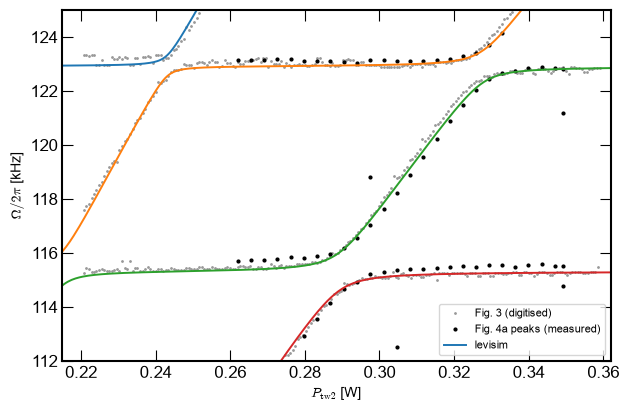

In [ ]:
P_SCAN = np.linspace(0.215, 0.362, 295)
F_scan, Γ_scan = map(np.array, zip(*[branches(P, Ω_BARE) for P in P_SCAN]))

fig, ax = plt.subplots(figsize=(6.4, 4.2))
for name, curve in data['fig3']['branches'].items():
    ax.plot(curve['P_W'], curve['f_kHz'], '.', color='0.6', ms=2, label='Fig. 3 (digitised)' if name == 'red' else None)
P4 = [(s['P_W'], f) for s in data['fig4a']['power_steps'] for f in s['peaks_kHz']]
ax.plot(*zip(*P4), 'k.', ms=4, label='Fig. 4a peaks (measured)')
for r in range(4):
    ax.plot(P_SCAN, F_scan[:, r]/kHz, '-', color=f'C{r}', lw=1.4, label='levisim' if r == 0 else None)
ax.set_xlim(0.215, 0.362)
ax.set_ylim(112, 125)
ax.set_xlabel(r'$P_\mathrm{tw2}$ [W]')
ax.set_ylabel(r'$\Omega/2\pi$ [kHz]')
ax.legend(loc='lower right', fontsize=8)
fig.tight_layout()

The splittings are the minimal distances between the two branches of each crossing. For the digitised
data they come from a hyperbola fitted to both branches around each crossing,
$f_\pm = a + b(P - P_c) \pm \sqrt{s^2(P - P_c)^2 + \delta^2/4}$, which is less sensitive to the sampling
(3.5 mW steps in Fig. 4a) than the smallest measured gap.

In [ ]:
def hyperbola_splitting(upper, lower, guess):
    upper, lower = np.asarray(upper), np.asarray(lower)

    def residual(p):
        a, b, Pc, s, δ = p
        fu = a + b*(upper[:, 0] - Pc) + np.sqrt((s*(upper[:, 0] - Pc))**2 + δ**2/4)
        fl = a + b*(lower[:, 0] - Pc) - np.sqrt((s*(lower[:, 0] - Pc))**2 + δ**2/4)
        return np.r_[fu - upper[:, 1], fl - lower[:, 1]]
    r = least_squares(residual, guess, loss='soft_l1', f_scale=0.1)
    cov = np.linalg.pinv(r.jac.T @ r.jac)*np.sum(r.fun**2)/(len(r.fun) - 5)
    return abs(r.x[4]), np.sqrt(cov[4, 4]), r.x[2]


def fig3_pairs(up, lo, a, b):
    U, L = data['fig3']['branches'][up], data['fig3']['branches'][lo]
    return ([(P, f) for P, f in zip(U['P_W'], U['f_kHz']) if a < P < b], [(P, f) for P, f in zip(L['P_W'], L['f_kHz']) if a < P < b])


def fig4a_pairs(lo_f, hi_f, a, b):
    U, L = [], []
    for step in data['fig4a']['power_steps']:
        peaks = sorted(f for f in step['peaks_kHz'] if lo_f < f < hi_f)
        if a <= step['P_W'] <= b and len(peaks) == 2:
            L.append((step['P_W'], peaks[0]))
            U.append((step['P_W'], peaks[1]))
    return U, L


measured = {
    'Fig. 3': {'x1x2': hyperbola_splitting(*fig3_pairs('green', 'orange', 0.29, 0.36), [119, 97, 0.325, 97, 1.2]),
               'y1x2': hyperbola_splitting(*fig3_pairs('orange', 'blue', 0.265, 0.32), [115, 100, 0.29, 100, 1.2]),
               'x1y2': hyperbola_splitting(*fig3_pairs('red', 'green', 0.22, 0.26), [120, 115, 0.244, 115, 1.0])},
    'Fig. 4a': {'x1x2': hyperbola_splitting(*fig4a_pairs(119.4, 126.0, 0.305, 0.348), [120, 95, 0.327, 95, 1.2]),
                'y1x2': hyperbola_splitting(*fig4a_pairs(112.0, 119.2, 0.276, 0.312), [116, 95, 0.291, 95, 1.2])},
}
text = data['text_values']['splittings_kHz']
models = {
    'levisim, Coulomb as ½k(x1-x2)²': {n: min_splitting(n, Ω_BARE) for n in CROSSINGS},
    'levisim, Coulomb as Eq. (37)': {n: min_splitting(n, Ω_BARE, coul_sign=+1) for n in CROSSINGS},
    'levisim, no Coulomb coupling/shift': {n: min_splitting(n, Ω_BARE, coulomb=False, phase_drift=False) for n in CROSSINGS},
}
print(f'{"splitting δ/2π [kHz]":34s}' + ''.join(f'{n:>15s}' for n in CROSSINGS))
print(f'{"text (Discussion)":34s}' + ''.join(f'{text[n][0]:>9.2f} ± {text[n][1]:.2f}' for n in CROSSINGS))
for source, values in measured.items():
    print(f'{source + " (hyperbola fit)":34s}' + ''.join(
        f'{values[n][0]:>9.2f} ± {values[n][1]:.2f}' if n in values else f'{"-":>15s}' for n in CROSSINGS))
for label, values in models.items():
    print(f'{label:34s}' + ''.join(f'{values[n][0]/kHz:>15.3f}' for n in CROSSINGS))
print('crossing powers [mW], levisim:', {n: round(v[1]*1e3, 1) for n, v in models['levisim, Coulomb as ½k(x1-x2)²'].items()},
      '| Fig. 4a fit:', {n: round(v[2]*1e3, 1) for n, v in measured['Fig. 4a'].items()})

splitting δ/2π [kHz]                         x1x2           y1x2           x1y2           y1y2
text (Discussion)                      1.22 ± 0.06     1.20 ± 0.06     1.02 ± 0.06     0.78 ± 0.05
Fig. 3 (hyperbola fit)                 1.11 ± 0.03     1.52 ± 0.03     0.71 ± 0.06              -
Fig. 4a (hyperbola fit)                1.25 ± 0.02     1.53 ± 0.02              -              -
levisim, Coulomb as ½k(x1-x2)²              1.192          1.409          0.775          1.246
levisim, Coulomb as Eq. (37)                0.720          1.316          0.866          0.752
levisim, no Coulomb coupling/shift          0.953          1.354          0.880          1.235
crossing powers [mW], levisim: {'x1x2': np.float64(327.7), 'y1x2': np.float64(289.1), 'x1y2': np.float64(243.0), 'y1y2': np.float64(214.2)} | Fig. 4a fit: {'x1x2': np.float64(328.6), 'y1x2': np.float64(292.2)}


## Can the paper's model reproduce the splittings quoted in the text?

The supplement fits $\zeta$, $\varphi$ and $\phi_1$ (at fixed $\theta_z$) to the three splittings of the text.
Below, the paper's own reduced model (Eq. (21), cavity eliminated, with the intra-particle terms
$G_{x_1y_1}$, $G_{x_2y_2}$ that Eq. (21) contains, the Coulomb matrix and the Coulomb-shifted phase) is
evaluated on a grid of $(\zeta, \varphi, \phi_1)$ and the best $\chi^2$ against the three quoted splittings is
printed. The reduced model is first checked against levisim's full model. The couplings scale as
$g_{\alpha 1} \propto \sin\phi_1$ and $g_{\alpha 2} \propto \zeta\sin\phi_2$ from the fitted values; the grid is
coarse (6° in $\varphi$, 0.035 rad in $\phi_1$ over 0.35-2.8 rad, six values of $\zeta$), enough to locate the minimum.

In [ ]:
G_FIT = np.array([18.1, 17.3, 7.0, 6.0])*kHz   # g_x1, g_y1, and g_x2, g_y2 at 220 mW (paper)
PHI2_FIT = PHI1 + K1064*R12*THETA_Z


def reduced_D(P, ζ, φ, ϕ1, Ω_bare=Ω_BARE, coul_sign=-1, intra=True, dz_scale=1.0, coulomb=True):
    """the supplement's D (Eq. (21) + Coulomb, Eq. (37) with sign coul_sign off the diagonal), vectorised"""
    P, ζ, φ, ϕ1 = np.broadcast_arrays(*(np.asarray(v, float) for v in (P, ζ, φ, ϕ1)))
    s = np.sqrt(P/0.36)
    ω = np.stack([np.full(P.shape, Ω_bare[0]), np.full(P.shape, Ω_bare[1]), Ω_bare[2]*s, Ω_bare[3]*s], -1)
    φ_eff = φ - dz_scale*K1064*np.vectorize(Δz)(P)
    f1 = np.sin(ϕ1)/np.sin(PHI1)
    f2 = (ζ/ZETA)*np.sin(ϕ1 + K1064*R12*THETA_Z)/np.sin(PHI2_FIT)*(0.22/P)**0.25*np.exp(1j*φ_eff)
    g = -np.stack([G_FIT[0]*f1, G_FIT[1]*f1, G_FIT[2]*f2, G_FIT[3]*f2], -1).astype(complex)
    ga, gb, ωb = g[..., :, None], g[..., None, :], ω[..., None, :]
    D = ga*np.conj(gb)/(-425*kHz - ωb - 1j*57*kHz/2) + np.conj(ga)*gb/(-425*kHz + ωb + 1j*57*kHz/2)
    if not intra:
        D[..., [0, 1, 2, 3], [1, 0, 3, 2]] = 0
    gc = -KC/(2*M_BEAD*R12**3) if coulomb else 0.0
    D[..., range(4), range(4)] += ω + gc/ω
    for a, b in ((0, 2), (2, 0), (1, 3), (3, 1)):
        D[..., a, b] += coul_sign*gc/np.sqrt(ω[..., a]*ω[..., b])
    return D


def reduced_splittings(ζ, φ, ϕ1, nP=31, **kwargs):
    ζ, φ, ϕ1 = np.broadcast_arrays(*(np.asarray(v, float) for v in (ζ, φ, ϕ1)))
    out = {}
    for name, (r, a, b) in CROSSINGS.items():
        P = np.linspace(a, b, nP)
        ev = np.sort(np.linalg.eigvals(reduced_D(P, ζ[..., None], φ[..., None], ϕ1[..., None], **kwargs)).real, -1)[..., ::-1]
        out[name] = (ev[..., r] - ev[..., r + 1]).min(-1)
    return out


at_fit = reduced_splittings(ZETA, PHI, PHI1, nP=401)
print('reduced model at the fitted parameters [kHz]:', {n: round(float(v)/kHz, 3) for n, v in at_fit.items()},
      '\nlevisim full model                         :', {n: round(v[0]/kHz, 3) for n, v in models['levisim, Coulomb as ½k(x1-x2)²'].items()})

δ_text = np.array([text[n][0] for n in ('x1x2', 'y1x2', 'x1y2')])
σ_text = np.array([text[n][1] for n in ('x1x2', 'y1x2', 'x1y2')])
print('\nreduced model at the fitted ζ, φ, ϕ1 [kHz]          x1x2   y1x2   x1y2   y1y2   χ² (text, 3)')
for label, kwargs in (('Eq. (21) as written, Coulomb ½k(x1-x2)²', {}), ('Eq. (21) as written, Coulomb Eq. (37)', dict(coul_sign=+1)),
                      ('Eq. (21) as written, no Coulomb', dict(coulomb=False, dz_scale=0.0)),
                      ('no intra-particle G, Coulomb Eq. (37)', dict(intra=False, coul_sign=+1)),
                      ('no intra-particle G, no Coulomb', dict(intra=False, coulomb=False, dz_scale=0.0))):
    v = np.array([float(x)/kHz for x in reduced_splittings(ZETA, PHI, PHI1, nP=401, **kwargs).values()])
    print(f'{label:46s}' + ''.join(f'{x:7.3f}' for x in v) + f'{(((v[:3] - δ_text)/σ_text)**2).sum():9.1f}')
print()
φ_grid, ϕ1_grid = np.meshgrid(np.arange(0, 360, 6)*degrees, np.arange(0.35, 2.80, 0.035), indexing='ij')
for label, kwargs in (('Coulomb as ½k(x1-x2)²', dict(coul_sign=-1)), ('Coulomb as Eq. (37)', dict(coul_sign=+1)),
                      ('Eq. (37), Δz × 2.2 (300 nm)', dict(coul_sign=+1, dz_scale=2.2))):
    best = None
    for ζ in (0.30, 0.35, 0.40, 0.45, 0.55, 0.65):
        s = reduced_splittings(ζ, φ_grid, ϕ1_grid, **kwargs)
        S = np.stack([s[n]/kHz for n in ('x1x2', 'y1x2', 'x1y2')], -1)
        χ2 = (((S - δ_text)/σ_text)**2).sum(-1)
        i = np.unravel_index(np.argmin(χ2), χ2.shape)
        if best is None or χ2[i] < best[0]:
            best = (χ2[i], ζ, φ_grid[i]/degrees, ϕ1_grid[i], S[i])
    χ2_fit = (((np.array([at_fit[n]/kHz for n in ('x1x2', 'y1x2', 'x1y2')]) if kwargs.get('coul_sign') == -1 else
                np.array([float(v)/kHz for v in reduced_splittings(ZETA, PHI, PHI1, nP=401, **kwargs).values()][:3])) - δ_text)/σ_text)**2
    print(f'{label:28s}: χ² at the paper\'s fit = {χ2_fit.sum():6.1f}; best on the grid χ² = {best[0]:5.1f} at ζ = {best[1]:.2f}, '
          f'φ = {best[2]:.0f}°, ϕ1 = {best[3]:.2f} → δ = {np.round(best[4], 2)} kHz')

reduced model at the fitted parameters [kHz]: {'x1x2': 1.139, 'y1x2': 1.427, 'x1y2': 0.714, 'y1y2': 1.231} 
levisim full model                         : {'x1x2': np.float64(1.192), 'y1x2': np.float64(1.409), 'x1y2': np.float64(0.775), 'y1y2': np.float64(1.246)}

reduced model at the fitted ζ, φ, ϕ1 [kHz]          x1x2   y1x2   x1y2   y1y2   χ² (text, 3)
Eq. (21) as written, Coulomb ½k(x1-x2)²         1.139  1.427  0.714  1.231     42.0
Eq. (21) as written, Coulomb Eq. (37)           0.673  1.320  0.823  0.745     98.0
Eq. (21) as written, no Coulomb                 0.904  1.366  0.823  1.227     46.2
no intra-particle G, Coulomb Eq. (37)           0.918  1.137  0.996  0.596     26.7
no intra-particle G, no Coulomb                 1.154  1.129  1.071  1.037      3.3

Coulomb as ½k(x1-x2)²       : χ² at the paper's fit =   42.0; best on the grid χ² =   0.9 at ζ = 0.65, φ = 198°, ϕ1 = 0.56 → δ = [1.21 1.24 0.98] kHz
Coulomb as Eq. (37)         : χ² at the paper's fit =   98.0; best on the

## Stability across the scan

levisim's stability report (`MultiTrap.is_stable`, from the eigenvalues of the drift matrix) for the system
without the Coulomb term, and the largest real part of the eigenvalues with it.

In [ ]:
unstable, unstable_C, growth, growth_C = [], [], [], []
P_STAB = np.linspace(0.215, 0.362, 1471)   # 0.1 mW steps
for P in P_STAB:
    m, A = pair_drift(P, Ω_BARE)
    λ = np.linalg.eigvals(A)
    growth.append(m.max_growth_rate)
    growth_C.append(λ.real.max())
    if not m.is_stable:
        unstable.append((P, *m.least_stable_mode))
    if λ.real.max() > m.stability_tolerance:
        k = np.argmax(λ.real)
        unstable_C.append((P, abs(λ[k].imag), λ[k].real))
print(f'{len(P_STAB)} powers from {P_STAB[0]*1e3:.0f} to {P_STAB[-1]*1e3:.0f} mW in 0.1 mW steps, fitted parameters '
      f'(φ = 172° with the Coulomb-shifted phase)')
for label, rows, g in (('levisim MultiTrap (no Coulomb coupling)', unstable, growth), ('with the Coulomb coupling', unstable_C, growth_C)):
    print(f'  {label}: unstable at {len(rows)} powers; max Re λ = {max(g):+.3g} /s')
    windows = []   # contiguous runs of unstable powers
    for row in rows:
        if windows and row[0] - windows[-1][-1][0] < 0.5e-3:
            windows[-1].append(row)
        else:
            windows.append([row])
    for w in windows:
        worst = max(w, key=lambda r: r[2])
        print(f'    {w[0][0]*1e3:.1f}-{w[-1][0]*1e3:.1f} mW: growth up to {worst[2]:.3f} /s on the mode at {worst[1]/kHz:.2f} kHz')
print(f'  bare-frequency crossings: y1-y2 at {Ω_BARE[1]**2/Ω_BARE[3]**2*0.36*1e3:.1f} mW, x1-y2 at {Ω_BARE[0]**2/Ω_BARE[3]**2*0.36*1e3:.1f} mW, '
      f'y1-x2 at {Ω_BARE[1]**2/Ω_BARE[2]**2*0.36*1e3:.1f} mW, x1-x2 at {Ω_BARE[0]**2/Ω_BARE[2]**2*0.36*1e3:.1f} mW; '
      f'φ - kΔz = {(PHI - K1064*Δz(0.219))/degrees:.0f}° at 219 mW, {(PHI - K1064*Δz(0.248))/degrees:.0f}° at 248 mW, '
      f'{(PHI - K1064*Δz(0.297))/degrees:.0f}° at 297 mW, {(PHI - K1064*Δz(0.336))/degrees:.0f}° at 336 mW')
print(f'  gas damping of each mode: Γ/2π = {m.dimensions["x1"].Γ/Hz:.4f} Hz (Re λ = {-m.dimensions["x1"].Γ/2:.4f} /s)')
for label, kwargs in (('φ = π, no Coulomb shift', dict(φ=π, phase_drift=False)), ('φ = 0, no Coulomb shift', dict(φ=0.0, phase_drift=False))):
    worst = max(np.linalg.eigvals(pair_drift(P, Ω_BARE, **kwargs)[1]).real.max() for P in P_STAB[::5])
    print(f'  {label}: max Re λ over the scan = {worst:+.3g} /s')

1471 powers from 215 to 362 mW in 0.1 mW steps, fitted parameters (φ = 172° with the Coulomb-shifted phase)
  levisim MultiTrap (no Coulomb coupling): unstable at 29 powers; max Re λ = +1.51 /s
    218.3-220.3 mW: growth up to 1.514 /s on the mode at 116.94 kHz
    247.5-248.2 mW: growth up to 0.163 /s on the mode at 124.36 kHz
  with the Coulomb coupling: unstable at 7 powers; max Re λ = +0.132 /s
    247.5-248.1 mW: growth up to 0.132 /s on the mode at 124.24 kHz
  bare-frequency crossings: y1-y2 at 220.1 mW, x1-y2 at 248.2 mW, y1-x2 at 296.8 mW, x1-x2 at 334.6 mW; φ - kΔz = 144° at 219 mW, 159° at 248 mW, 178° at 297 mW, 189° at 336 mW
  gas damping of each mode: Γ/2π = 0.0044 Hz (Re λ = -0.0138 /s)
  φ = π, no Coulomb shift: max Re λ over the scan = -0.0247 /s
  φ = 0, no Coulomb shift: max Re λ over the scan = -0.0169 /s


On the red side with an almost conservative interaction the system is stable except near two bare
crossings, where the Coulomb-shifted phase $\varphi - k\Delta z$ is furthest from $\pi$ (printed above): there the
pseudo-dark mode, which the cavity no longer damps, picks up a small gain from the non-reciprocal part
of the coupling, larger than the 0.0044 Hz gas damping. For $\varphi = 0$ or $\pi$ every mode is damped at
least at the gas rate over the whole scan.

## Dark modes (Fig. 4)

At the crossing of the *bare* frequencies the combination of the two modes that does not drive the cavity
decouples from it: it is undamped by the cavity and invisible in the cavity output. The supplement's
two-mode analysis (Sec. I B) shows that this happens at $\delta\omega = 0$ for any $\zeta$, whereas the
minimal splitting sits at $\delta\omega = (1 - \zeta^2)g^2/\Delta$, so the dark point lies above the avoided
crossing in $P_\text{tw2}$. Below: levisim's heterodyne spectrogram (shot-noise units, with photon recoil) for
(a) the fitted parameters with the Coulomb terms and (b) $\varphi = \pi$ without the Coulomb shift, as in
Fig. 4b; and the optical linewidth of the upper branch, which vanishes at the dark point.

heterodyne helper against MultiTrap.heterodyne_spectrum: max relative difference 2.2e-15


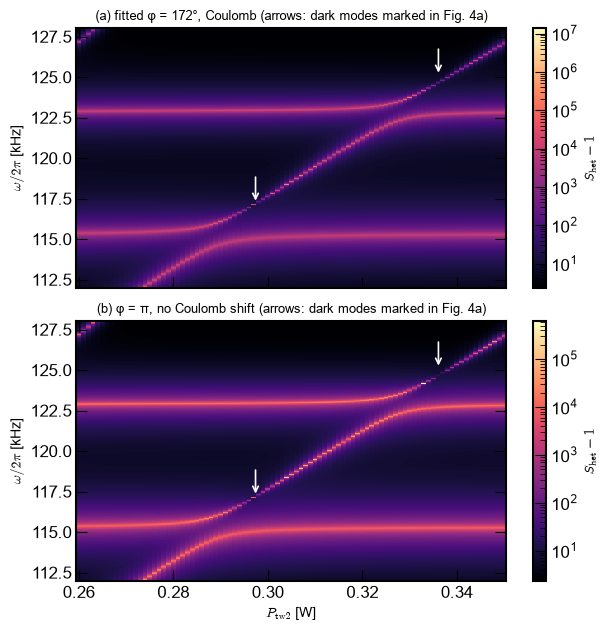

In [ ]:
m_check, A_check = pair_drift(0.30, Ω_BARE, coulomb=False, ω_range=np.linspace(114, 124, 6)*kHz)
lam = np.asarray(m_check.heterodyne_spectrum(QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL)).real
print(f'heterodyne helper against MultiTrap.heterodyne_spectrum: max relative difference '
      f'{np.max(np.abs(heterodyne(m_check, m_check.ω_range)/lam - 1)):.1e}')

P_DARK = np.arange(0.260, 0.3501, 0.001)
ω_spec = np.linspace(112, 128, 641)*kHz
spectrograms = {}
for label, kwargs in (('(a) fitted φ = 172°, Coulomb', {}), ('(b) φ = π, no Coulomb shift', dict(φ=π, phase_drift=False))):
    rows = []
    for P in P_DARK:
        m, A = pair_drift(P, Ω_BARE, **kwargs)
        rows.append(heterodyne(m, ω_spec, drift_matrix=A) - 1)
    spectrograms[label] = np.array(rows)

fig, axes = plt.subplots(2, 1, figsize=(6.2, 6.4), sharex=True)
for ax, (label, S) in zip(axes, spectrograms.items()):
    mesh = ax.pcolormesh(P_DARK, ω_spec/kHz, S.T, norm=LogNorm(np.percentile(S, 5), S.max()), cmap='magma', shading='nearest')
    for arrow in data['fig4a']['dark_mode_arrows']:
        ax.annotate('', xy=(arrow['P_W'], arrow['f_kHz'] - 0.6), xytext=(arrow['P_W'], arrow['f_kHz'] + 1.2),
                    arrowprops=dict(arrowstyle='->', color='w', lw=1.2))
    ax.set_ylabel(r'$\omega/2\pi$ [kHz]')
    ax.set_title(label + ' (arrows: dark modes marked in Fig. 4a)', fontsize=9)
    fig.colorbar(mesh, ax=ax, label=r'$S_\mathrm{het} - 1$')
axes[-1].set_xlabel(r'$P_\mathrm{tw2}$ [W]')
fig.tight_layout()

                               crossing  min gap  dark at    γ_dark  γ_bright
fitted φ = 172°, Coulomb           y1x2  289.1mW  296.7mW   0.004Hz   193.8Hz  (gap 1.409 kHz)
fitted φ = 172°, Coulomb           x1x2  327.7mW  336.2mW   0.066Hz   104.1Hz  (gap 1.192 kHz)
φ = π, no Coulomb shift            y1x2  289.1mW  296.7mW   0.004Hz   193.8Hz  (gap 1.413 kHz)
φ = π, no Coulomb shift            x1x2  327.6mW  336.3mW   0.004Hz   104.1Hz  (gap 1.199 kHz)
φ = 0, no Coulomb shift            y1x2  288.8mW  296.8mW   0.004Hz   193.2Hz  (gap 1.326 kHz)
φ = 0, no Coulomb shift            x1x2  327.9mW  332.9mW   0.005Hz   100.6Hz  (gap 0.702 kHz)
φ = π, no Coulomb at all           y1x2  289.1mW  296.7mW   0.005Hz   192.0Hz  (gap 1.366 kHz)
φ = π, no Coulomb at all           x1x2  327.7mW  334.6mW   0.004Hz   104.6Hz  (gap 0.962 kHz)
Fig. 4a arrows (measured): 297.4, 336.1 mW (power steps of 3.5 mW); Fig. 4b dark points: 295.5, 334.5 mW; gas damping γ_gas/2π = 0.0044 Hz


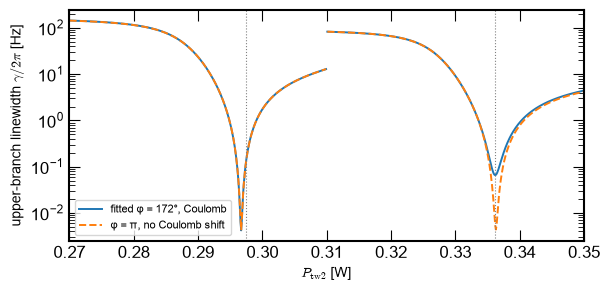

In [ ]:
P_FINE = np.linspace(0.27, 0.35, 801)
widths = {}
print(f'{"":30s}{"crossing":>9s}{"min gap":>9s}{"dark at":>9s}{"γ_dark":>10s}{"γ_bright":>10s}')
for label, kwargs in (('fitted φ = 172°, Coulomb', {}), ('φ = π, no Coulomb shift', dict(φ=π, phase_drift=False)),
                      ('φ = 0, no Coulomb shift', dict(φ=0.0, phase_drift=False)),
                      ('φ = π, no Coulomb at all', dict(φ=π, coulomb=False, phase_drift=False))):
    F, W = map(np.array, zip(*[branches(P, Ω_BARE, **kwargs) for P in P_FINE]))
    widths[label] = W
    for name in ('y1x2', 'x1x2'):
        r, a, b = CROSSINGS[name]
        sel = (P_FINE > a) & (P_FINE < b)
        gap = F[sel, r] - F[sel, r + 1]
        jg, jd = np.argmin(gap), np.argmin(W[sel, r])
        print(f'{label:30s}{name:>9s}{P_FINE[sel][jg]*1e3:7.1f}mW{P_FINE[sel][jd]*1e3:7.1f}mW'
              f'{W[sel, r][jd]/Hz:8.3f}Hz{W[sel, r + 1][jd]/Hz:8.1f}Hz  (gap {gap[jg]/kHz:.3f} kHz)')
arrows = [a['P_W']*1e3 for a in data['fig4a']['dark_mode_arrows']]
print(f'Fig. 4a arrows (measured): {arrows[0]:.1f}, {arrows[1]:.1f} mW (power steps of 3.5 mW); '
      f'Fig. 4b dark points: {data["fig4b"]["dark_points_W"]["y1x2"]*1e3:.1f}, {data["fig4b"]["dark_points_W"]["x1x2"]*1e3:.1f} mW; '
      f'gas damping γ_gas/2π = {pontin_pair(0.3).dimensions["x1"].Γ/Hz:.4f} Hz')

fig, ax = plt.subplots(figsize=(6.2, 3.0))
for (label, W), style in zip(list(widths.items())[:2], ('-', '--')):
    # the upper branch of each crossing: branch 2 below 0.31 W, branch 1 above
    # (two separate curves: the y1x2 crossing below 0.31 W, the x1x2 crossing above)
    low, high = P_FINE < 0.31, P_FINE > 0.31
    line, = ax.semilogy(P_FINE[low], W[low, 2]/Hz, style, lw=1.4, label=label)
    ax.semilogy(P_FINE[high], W[high, 1]/Hz, style, lw=1.4, color=line.get_color())
for arrow in data['fig4a']['dark_mode_arrows']:
    ax.axvline(arrow['P_W'], color='0.5', lw=0.8, ls=':')
ax.set_xlabel(r'$P_\mathrm{tw2}$ [W]')
ax.set_ylabel(r'upper-branch linewidth $\gamma/2\pi$ [Hz]')
ax.set_xlim(0.27, 0.35)
ax.legend(fontsize=8, loc='lower left')
fig.tight_layout()

## Summary

All numbers below are printed by the cells above.

**Agreement.**

- **Two tweezers, one cavity drive.** With the 976 nm bead scattering $\zeta$ = 0.35 of the 1064 nm focal
  field (`cavity_drive_tweezer`, `cavity_drive_field_ratio`) and sitting at $\phi_2 = \phi_1 + k r_{12}\theta_z$,
  levisim's couplings of particle 2 follow the paper's $(P_0/P_\text{tw2})^{1/4}$ law with no further
  freedom: 7.042 and 6.104 kHz against 7.0 and 6.0 kHz at 220 mW, within 0.7 % ($x$) and 1.9 % ($y$) over the
  scan. Driving the cavity with the 976 nm tweezer itself instead gives a WARNING and couplings for
  particle 2 (30.5 and 28.5 kHz at 220 mW) about three times those with the 1064 nm drive.
- **Frequencies.** Calibrated to the Fig. 3 levels and the three quoted crossing powers, the bare
  frequencies are 124.46, 117.22 and 129.11 kHz (stated 124, 117, 129) and 149.90 kHz for $y_2$ at 360 mW
  (stated 148). The fourth crossing then falls at 214.2 mW (the paper's estimate: 214 mW). The four
  branches follow Fig. 3 and the measured peaks of Fig. 4a over the whole scan.
- **Splittings visible in the figures.** With the paper's fitted $\zeta$, $\varphi$, $\phi_1$, $\theta_z$, the
  Coulomb coupling from $\tfrac12 k(x_1 - x_2)^2$ and the Coulomb-shifted phase, levisim's full model gives
  1.192 ($x_1x_2$), 1.409 ($y_1x_2$) and 0.775 kHz ($x_1y_2$), against 1.25 ± 0.02 and 1.53 ± 0.02 kHz from
  hyperbola fits to the measured peaks of Fig. 4a and 1.11, 1.52 and 0.71 kHz from the curves of Fig. 3
  (within 5 %, 8 % and 9 %). The paper's own reduced model (Eq. (21), cavity eliminated) agrees with levisim's
  full model within 8 %.
- **Dark modes.** The upper branch goes dark at 296.7 and 336.2 mW, about 8 mW above the minimal splittings
  (289.1 and 327.7 mW), where the bare frequencies cross; the paper marks the dark modes in the measured
  spectrogram (Fig. 4a) at 297.4 and 336.1 mW (power steps of 3.5 mW), and its analytic Fig. 4b has them at
  about 295.5 and 334.5 mW. There the cavity damping of the upper branch falls from about 100-200 Hz to the gas
  damping (0.0044 Hz) for $\varphi = 0$ or $\pi$, and to 0.066 Hz for the fitted 172° at the $x_1x_2$ crossing
  (a pseudo-dark mode). levisim's spectrogram reproduces the dimming of the upper branch in Fig. 4.

**Discrepancies and open points.**

- **Absolute couplings.** The stated waist (0.58 μm), $\theta$ = 45° and a nominal 125 nm, 2200 kg/m³ sphere give
  $g_{x1}/2\pi$ = 24.6 kHz, 1.36 times the fitted 18.1 kHz; the paper's $g_{x1}/g_{y1}$ = 1.046 needs
  $\theta$ = 47.1°. The paper does not list the nominal parameters behind its $g_0$, so levisim's drive field
  (waist 0.847 μm) and $\theta$ are calibrated to the fitted couplings.
- **Splittings quoted in the text.** The text gives 1.22, 1.20 and 1.02 kHz (and estimates 0.78 kHz for
  $y_1y_2$). The $y_1x_2$ value differs from the 1.52-1.53 kHz read from both Figs. 3 and 4a, and the
  $x_1y_2$ value from the 0.71 kHz of Fig. 3 (provisional: digitised from the curves near the edge of the
  scan). The paper's model as written (Eq. (21) with its intra-particle terms $G_{x_1y_1}$, $G_{x_2y_2}$,
  about 1.6 kHz) at the fitted parameters gives $\chi^2$ = 42 against the three quoted values; dropping the
  intra-particle terms and the Coulomb coupling gives $\chi^2$ = 3.3 (1.154, 1.129, 1.071 kHz). A grid search
  of the full model reaches $\chi^2$ = 0.9 only far from the published fit ($\zeta$ = 0.65, $\phi_1$ = 0.56 rad).
  The intra-particle hybridisation weakens the $x_1$-like mode's coupling and strengthens the $y_1$-like one,
  which is why the full model has $\delta_{y_1x_2} > \delta_{x_1x_2}$, as the figures do.
- **Coulomb terms.** Expanding $\tfrac12 k_{x,y}(x_1 - x_2)^2$ (Eq. (36)) gives the off-diagonal Coulomb
  entries the opposite sign to the diagonal ones; Eq. (37) prints them with the same sign. With Eq. (37) as
  printed, the $x_1x_2$ splitting at the fitted parameters falls to 0.72 kHz, against 1.25 kHz measured.
  The nominal charges and mass give $g_C/2\pi$ = 91 Hz (paper: 120 Hz, used here) and a Coulomb shift of
  150 nm (51° of phase) over the scan, where the supplement says about 300 nm (110°); the density and the
  charge signs are not stated.
- **Fourth crossing.** levisim predicts $\delta_{y_1y_2}$ = 1.25 kHz at 214 mW, outside the scan, against the
  paper's estimate of 0.78 ± 0.05 kHz.
- **Linear stability.** With the fitted phase, the Coulomb-shifted phase $\varphi - k\Delta z$ reaches 144° near
  the $y_1y_2$ bare crossing (220 mW) and 159° near the $x_1y_2$ one (248 mW). There the non-reciprocal part of the
  cavity-mediated coupling gives the pseudo-dark mode a small gain that exceeds the gas damping: levisim's
  `MultiTrap` reports the system unstable in 218.3-220.3 mW (growth up to 1.51 /s) and 247.5-248.2 mW
  (0.16 /s); with the Coulomb coupling only the second window remains. The windows are narrower than the
  3.5 mW power steps, and any damping above about 0.5 Hz (e.g. feedback, not mentioned in the paper) removes
  them. For $\varphi$ = 0 or $\pi$ the system is stable over the whole scan.
- **Data.** The figures are raster images, so all data are digitised from pixels (about 0.05 kHz and
  0.3 mW per pixel); the measured levels of Fig. 4a sit about 0.25 kHz above those of Fig. 3.

**Notes on the text** (neutral observations, none of which changes the comparison above):

- Supplement Eq. (23) writes $G_{00}$ with $\mp i\kappa/2$ where Eq. (19) has $\pm i\kappa/2$, so the
  imaginary parts in Eqs. (27) and (30) have the opposite sign to the main text's
  $\mathrm{Im}[\lambda_-] = (1 + \zeta^2)\,2\kappa g^2\omega_0/\Delta^3$ (damping for $\Delta < 0$, as Eq. (19) gives).
  Eq. (30) has $\Delta^3$ inside the bracket where Eq. (27) has $\Delta^2$.
- The phase used for Fig. 4b is $\pi$ in the caption and zero in the text. Without the Coulomb terms the
  cavity-mediated coupling has period $\pi$ in $\varphi$, so both give a dark mode; with them they differ
  (the $x_1x_2$ dark point moves from 336.3 mW at $\pi$ to 332.9 mW at 0).
- The crossing powers are given as 0.32, 0.29, 0.24 W (Fig. 2), 326, 291, 243 mW (Discussion) and 323, 289 mW
  (Fig. 4 caption). The Fig. 3 caption calls $(0.61, 0.6, 0.51)$ kHz coupling rates; they are half the quoted
  splittings. Supplement Fig. 1(b) is labelled $\delta_{y_1y_2}$ in the list of maps and $\delta_{y_1x_2}$ in
  the text. The waists in Sec. III A are printed without a unit.

In [ ]:
print(f'notebook runtime: {time.time() - T_START:.1f} s')

notebook runtime: 75.8 s
